In [35]:
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, precision_score,
    recall_score, confusion_matrix
)
from tqdm import tqdm


In [36]:
df = pd.read_parquet("train_multilabel_combined.parquet")


In [37]:
df.head()

,molecule_smiles,BRD4,HSA,sEH
0,O=C(N[Dy])[C@H]1CC[C@H](CNc2nc(NCCC3SCCS3)nc(Nc3nc(F)cc(F)n3)n2)CC1,0,0,1
1,Cc1cnc(CCNc2nc(NCCN3CC[C@@H](O)C3)nc(Nc3cc4ccccc4cc3C(=O)N[Dy])n2)s1,0,0,0
2,Cc1cc(C)c(CNc2nc(NCc3c(F)cccc3N3CCCC3)nc(N[C@H](CC(=O)N[Dy])Cc3cccs3)n2)c(=O)[nH]1,0,0,0
3,O=C1OCc2cc(Nc3nc(NCC4CCCC5(CCC5)C4O)nc(NC[C@H]4CC[C@H](C(=O)N[Dy])CC4)n3)ccc21,0,0,1
4,O=C(N[Dy])c1cc(F)c(Nc2nc(NCCC3CSC3)nc(Nc3cccc(N4CCOCC4)c3)n2)c(F)c1,0,0,0


In [38]:
train_val, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df[["BRD4", "HSA", "sEH"]].values.tolist())
train_df, val_df = train_test_split(train_val, test_size=0.25, random_state=42, stratify=train_val[["BRD4", "HSA", "sEH"]].values.tolist())


In [39]:
from rdkit import Chem
import pandas as pd

def validated_downsample(df, target_patterns=['BRD4', 'HSA', 'sEH'], base_n=50000):
    """
    Robust downsampling with SMILES validation and error handling
    Args:
        df: Input DataFrame (must contain 'molecule_smiles' and target columns)
        target_patterns: List of target columns to create patterns
        base_n: Target count for non-binders
    Returns:
        Balanced DataFrame with valid SMILES
    """
    try:
        # Validate input columns
        required_columns = set(target_patterns + ['molecule_smiles'])
        missing_cols = required_columns - set(df.columns)
        if missing_cols:
            raise ValueError(f"Missing required columns: {missing_cols}")
        
        # Create pattern column safely
        df = df.copy()  # Avoid modifying original
        df['pattern'] = df[target_patterns].astype(str).agg(''.join, axis=1)
        
        # Validate SMILES
        df['is_valid'] = df['molecule_smiles'].apply(lambda x: Chem.MolFromSmiles(str(x)) is not None)
        valid_df = df[df['is_valid']].copy()
        
        # Split by pattern
        pattern_groups = valid_df.groupby('pattern')
        
        # Process non-binders
        non_binders = pattern_groups.get_group('000') if '000' in pattern_groups.groups else pd.DataFrame()
        sampled_non_binders = (non_binders.sample(n=min(base_n, len(non_binders)), 
                              random_state=42) if not non_binders.empty else pd.DataFrame())
        
        # Process binders (keep all)
        binders = [group for name, group in pattern_groups if name != '000']
        
        # Combine results
        balanced_df = pd.concat([sampled_non_binders] + binders)
        return balanced_df.sample(frac=1).drop(columns=['pattern', 'is_valid']).reset_index(drop=True)
    
    except Exception as e:
        print(f"Error in downsampling: {str(e)}")
        return df  # Return original if error occurs

In [40]:
# Check your columns first
print(train_df.columns.tolist())


['molecule_smiles', 'BRD4', 'HSA', 'sEH']


In [41]:
# If your target columns have different names:
train_df = validated_downsample(
    train_df,
    target_patterns=['BRD4', 'HSA', 'sEH'],
    base_n=100000
)

In [42]:
class MoleculeDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=128):
        self.smiles = df["molecule_smiles"].tolist()
        self.labels = df[["BRD4", "HSA", "sEH"]].values.astype(np.float32)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.smiles)

    def __getitem__(self, idx):
        inputs = self.tokenizer(self.smiles[idx], padding="max_length", truncation=True,
                                max_length=self.max_length, return_tensors="pt")
        return {
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx])
        }

tokenizer = AutoTokenizer.from_pretrained("seyonec/ChemBERTa-zinc-base-v1")
train_dataset = MoleculeDataset(train_df, tokenizer)
val_dataset = MoleculeDataset(val_df, tokenizer)
test_dataset = MoleculeDataset(test_df, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64)
test_loader = DataLoader(test_dataset, batch_size=64)


In [43]:
class MultiLabelChemBERTa(nn.Module):
    def __init__(self, model_name="seyonec/ChemBERTa-zinc-base-v1"):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        for param in self.encoder.parameters():
            param.requires_grad = False
        self.classifier = nn.Sequential(
            nn.Linear(self.encoder.config.hidden_size, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 3)
        )

    def forward(self, input_ids, attention_mask):
        output = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        pooled = output.last_hidden_state[:, 0]
        return self.classifier(pooled)


In [44]:
import torch
import torch.nn as nn
from transformers import AutoModel

class MultiLabelChemBERTaPlus(nn.Module):
    def __init__(self, model_name="seyonec/ChemBERTa-zinc-base-v1"):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        for param in self.encoder.parameters():
            param.requires_grad = False

        self.attn_weights = nn.Sequential(
            nn.Linear(self.encoder.config.hidden_size, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )

        self.classifier = nn.Sequential(
            nn.Linear(self.encoder.config.hidden_size * 2, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 3)
        )

    def forward(self, input_ids, attention_mask):
        output = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        last_hidden_state = output.last_hidden_state  # (B, T, H)

        # Mean Pooling
        mean_pool = (last_hidden_state * attention_mask.unsqueeze(-1)).sum(dim=1) / attention_mask.sum(dim=1, keepdim=True)

        # Attention Pooling
        attn_scores = self.attn_weights(last_hidden_state).squeeze(-1)  # (B, T)
        attn_scores = attn_scores.masked_fill(attention_mask == 0, -1e9)
        attn_weights = torch.softmax(attn_scores, dim=1)  # (B, T)
        attn_pool = torch.sum(last_hidden_state * attn_weights.unsqueeze(-1), dim=1)

        pooled = torch.cat([mean_pool, attn_pool], dim=1)  # (B, H*2)
        return self.classifier(pooled)


In [45]:
# Create a dummy input
dummy_input_ids = torch.randint(0, 100, (1, 128))  # (batch_size, seq_length)
dummy_attention_mask = torch.ones_like(dummy_input_ids)

# Instantiate your model
model = MultiLabelChemBERTaPlus()

# Get the output
output = model(dummy_input_ids, dummy_attention_mask)

In [46]:
from torchinfo import summary
from transformers import AutoTokenizer

# Define your model class (reuse your MultiLabelChemBERTaPlus)
model = MultiLabelChemBERTaPlus()

# Dummy input
tokenizer = AutoTokenizer.from_pretrained("seyonec/ChemBERTa-zinc-base-v1")
inputs = tokenizer("c1ccccc1", return_tensors="pt", padding="max_length", max_length=128, truncation=True)

# Model summary
summary(model, input_data=(inputs["input_ids"], inputs["attention_mask"]), depth=3, col_names=["input_size", "output_size", "num_params"])


Layer (type:depth-idx)                                            Input Shape               Output Shape              Param #
MultiLabelChemBERTaPlus                                           [1, 128]                  [1, 3]                    --
├─RobertaModel: 1-1                                               --                        [1, 768]                  --
│    └─RobertaEmbeddings: 2-1                                     --                        [1, 128, 768]             --
│    │    └─Embedding: 3-1                                        [1, 128]                  [1, 128, 768]             (589,056)
│    │    └─Embedding: 3-2                                        [1, 128]                  [1, 128, 768]             (768)
│    │    └─Embedding: 3-3                                        [1, 128]                  [1, 128, 768]             (394,752)
│    │    └─LayerNorm: 3-4                                        [1, 128, 768]             [1, 128, 768]             (1,536)
│    

In [47]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
import copy

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        BCE_loss = F.binary_cross_entropy_with_logits(inputs, targets, reduction='none')
        pt = torch.exp(-BCE_loss)
        focal_loss = (1 - pt) ** self.gamma * BCE_loss

        if self.alpha is not None:
            if self.alpha.device != inputs.device:
                self.alpha = self.alpha.to(inputs.device)
            focal_loss = self.alpha[targets.long()] * focal_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss


def train(model, optimizer, train_loader, criterion, device, epochs=10, val_loader=None,
          scheduler=None, early_stopping_patience=3, save_path="best_multilabel_model.pt"):
    model.to(device)

    train_losses, val_losses = [], []
    train_accs, val_accs = [], []

    best_val_loss = float('inf')
    best_model_state = copy.deepcopy(model.state_dict())
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        total_loss, correct, total = 0, 0, 0
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}")

        for batch in pbar:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device).float()

            optimizer.zero_grad()
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            preds = torch.sigmoid(logits) > 0.5
            correct += (preds == labels).sum().item()
            total += labels.numel()

            total_loss += loss.item()
            batch_acc = (preds == labels).float().mean().item()
            pbar.set_postfix({"loss": loss.item(), "batch_acc": batch_acc})

        epoch_loss = total_loss / len(train_loader)
        epoch_acc = correct / total
        train_losses.append(epoch_loss)
        train_accs.append(epoch_acc)
        print(f"Epoch {epoch+1} | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.4f}")

        # Validation
        if val_loader:
            model.eval()
            val_loss, val_correct, val_total = 0, 0, 0
            with torch.no_grad():
                for batch in val_loader:
                    input_ids = batch["input_ids"].to(device)
                    attention_mask = batch["attention_mask"].to(device)
                    labels = batch["labels"].to(device).float()

                    logits = model(input_ids, attention_mask)
                    val_loss += criterion(logits, labels).item()

                    preds = torch.sigmoid(logits) > 0.5
                    val_correct += (preds == labels).sum().item()
                    val_total += labels.numel()

            val_epoch_loss = val_loss / len(val_loader)
            val_epoch_acc = val_correct / val_total
            val_losses.append(val_epoch_loss)
            val_accs.append(val_epoch_acc)
            print(f"Epoch {epoch+1} | Val Loss: {val_epoch_loss:.4f} | Val Acc: {val_epoch_acc:.4f}")

            # Early Stopping Logic
            if val_epoch_loss < best_val_loss:
                best_val_loss = val_epoch_loss
                best_model_state = copy.deepcopy(model.state_dict())
                torch.save(best_model_state, save_path)  # ✅ Save best model
                print(f"✔️  Best model saved at epoch {epoch+1} with Val Loss: {val_epoch_loss:.4f}")
                patience_counter = 0
            else:
                patience_counter += 1
                print(f"EarlyStopping: {patience_counter}/{early_stopping_patience} patience used.")
                if patience_counter >= early_stopping_patience:
                    print("⏹️  Stopping early due to no improvement in validation loss.")
                    break

            # Scheduler step
            if scheduler:
                if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                    scheduler.step(val_epoch_loss)
                else:
                    scheduler.step()

    # Load best model state before returning
    model.load_state_dict(best_model_state)

    # Plot
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss')
    if val_loader: plt.plot(val_losses, label='Val Loss')
    plt.title('Loss Curve')
    plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(train_accs, label='Train Accuracy')
    if val_loader: plt.plot(val_accs, label='Val Accuracy')
    plt.title('Accuracy Curve')
    plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend()

    plt.tight_layout()
    plt.show()

    return {
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_accs': train_accs,
        'val_accs': val_accs
    }


In [48]:
def evaluate(model, loader, device):
    model.eval()
    all_labels, all_preds = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            logits = model(input_ids, attention_mask)
            preds = torch.sigmoid(logits).cpu().numpy()
            all_preds.append(preds)
            all_labels.append(labels.cpu().numpy())

    y_true = np.vstack(all_labels)
    y_pred = (np.vstack(all_preds) > 0.5).astype(int)

    print("Micro Accuracy:", accuracy_score(y_true, y_pred))
    print("F1 Micro:", f1_score(y_true, y_pred, average="micro"))
    print("F1 Macro:", f1_score(y_true, y_pred, average="macro"))
    print("Precision Macro:", precision_score(y_true, y_pred, average="macro", zero_division=0))
    print("Recall Macro:", recall_score(y_true, y_pred, average="macro", zero_division=0))
    print("ROC AUC Macro:", roc_auc_score(y_true, y_pred, average="macro"))

    for i, protein in enumerate(["BRD4", "HSA", "sEH"]):
        print(f"\nConfusion Matrix for {protein}:")
        print(confusion_matrix(y_true[:, i], y_pred[:, i]))


d:\Thesis_BME\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(
Epoch 1: 100%|██████████| 15717/15717 [15:19<00:00, 17.10it/s, loss=0.0566, batch_acc=0.854]


Epoch 1 | Train Loss: 0.0704 | Train Acc: 0.8751
Epoch 1 | Val Loss: 0.0703 | Val Acc: 0.8926
✔️  Best model saved at epoch 1 with Val Loss: 0.0703


Epoch 2: 100%|██████████| 15717/15717 [15:21<00:00, 17.05it/s, loss=0.0427, batch_acc=0.927]


Epoch 2 | Train Loss: 0.0607 | Train Acc: 0.8934
Epoch 2 | Val Loss: 0.0644 | Val Acc: 0.9021
✔️  Best model saved at epoch 2 with Val Loss: 0.0644


Epoch 3: 100%|██████████| 15717/15717 [15:21<00:00, 17.05it/s, loss=0.0496, batch_acc=0.885]


...

Epoch 8 | Train Loss: 0.0529 | Train Acc: 0.9074
Epoch 8 | Val Loss: 0.0612 | Val Acc: 0.9052
✔️  Best model saved at epoch 8 with Val Loss: 0.0612


Epoch 9: 100%|██████████| 15717/15717 [15:22<00:00, 17.05it/s, loss=0.0554, batch_acc=0.927]


Epoch 9 | Train Loss: 0.0526 | Train Acc: 0.9082
Epoch 9 | Val Loss: 0.0613 | Val Acc: 0.9034
EarlyStopping: 1/4 patience used.


Epoch 10: 100%|██████████| 15717/15717 [15:24<00:00, 17.01it/s, loss=0.0552, batch_acc=0.906]


Epoch 10 | Train Loss: 0.0524 | Train Acc: 0.9086
Epoch 10 | Val Loss: 0.0600 | Val Acc: 0.9053
✔️  Best model saved at epoch 10 with Val Loss: 0.0600


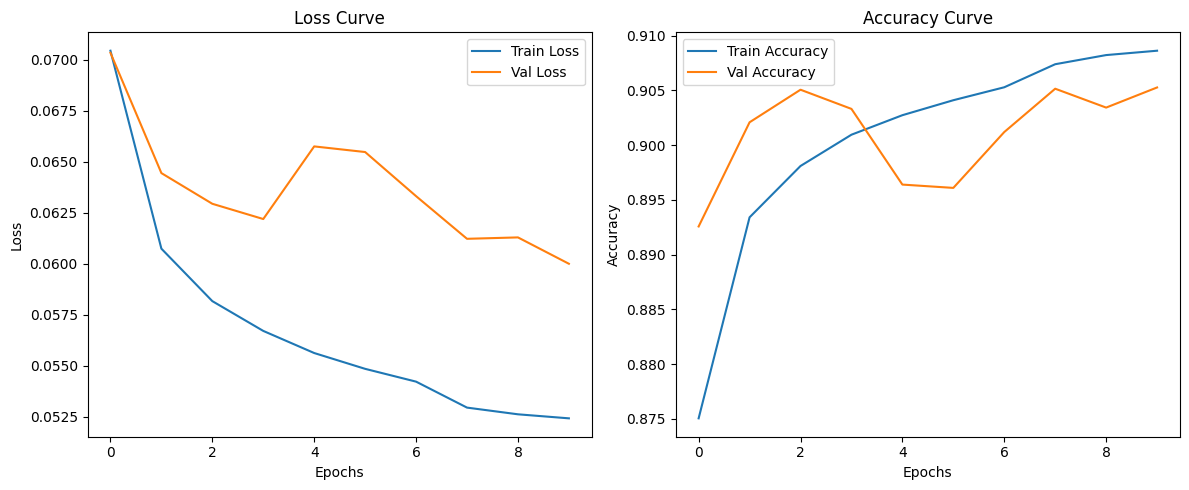

In [49]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MultiLabelChemBERTaPlus()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
alpha = None 
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5, verbose=True)


criterion = FocalLoss(alpha=alpha, gamma=2.0)

history = train(model, optimizer, train_loader, criterion, device,
                epochs=10, val_loader=val_loader, save_path="best_multilabel_model.pt",
                scheduler=scheduler, early_stopping_patience=4)

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix
)

def evaluation(model, loader, device):
    model.eval()
    all_labels, all_preds = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            logits = model(input_ids, attention_mask)
            preds = torch.sigmoid(logits).cpu().numpy()
            all_preds.append(preds)
            all_labels.append(labels.cpu().numpy())

    y_true = np.vstack(all_labels)
    y_pred = (np.vstack(all_preds) > 0.5).astype(int)

    print("\n✅ Evaluation Metrics")
    print("Micro Accuracy:", accuracy_score(y_true, y_pred))
    print("F1 Micro:", f1_score(y_true, y_pred, average="micro"))
    print("F1 Macro:", f1_score(y_true, y_pred, average="macro"))
    print("Precision Macro:", precision_score(y_true, y_pred, average="macro", zero_division=0))
    print("Recall Macro:", recall_score(y_true, y_pred, average="macro", zero_division=0))
    print("ROC AUC Macro:", roc_auc_score(y_true, y_pred, average="macro"))

    protein_names = ["BRD4", "HSA", "sEH"]
    for i, protein in enumerate(protein_names):
        cm = confusion_matrix(y_true[:, i], y_pred[:, i])
        cm_percent = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100
        print(f"\nConfusion Matrix for {protein} (Counts):")
        print(cm)

        # Plot confusion matrix (Percentages)
        plt.figure(figsize=(4, 3))
        sns.heatmap(cm_percent, annot=True, fmt=".2f", cmap="Blues", 
                    xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
        plt.xlabel("Predicted Label")
        plt.ylabel("Actual Label")
        plt.title(f"{protein} Confusion Matrix (%)")
        plt.tight_layout()
        plt.show()



✅ Evaluation Metrics
Micro Accuracy: 0.7441586263015427
F1 Micro: 0.7847823340305757
F1 Macro: 0.7684363118879158
Precision Macro: 0.6927299471966614
Recall Macro: 0.867368940212042
ROC AUC Macro: 0.8902362399716915

Confusion Matrix for BRD4 (Counts):
[[414398  36162]
 [  8372  83021]]


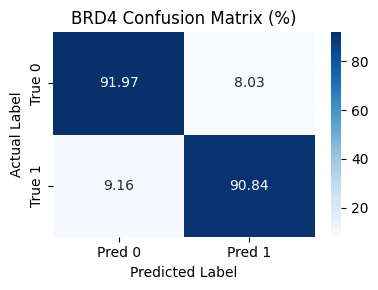


Confusion Matrix for HSA (Counts):
[[409029  51243]
 [ 18460  63221]]


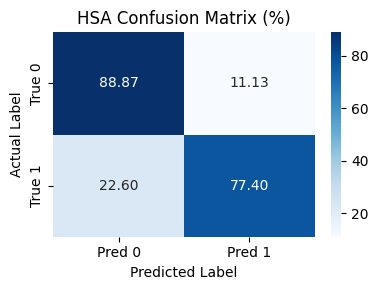


Confusion Matrix for sEH (Counts):
[[369614  27435]
 [ 11634 133270]]


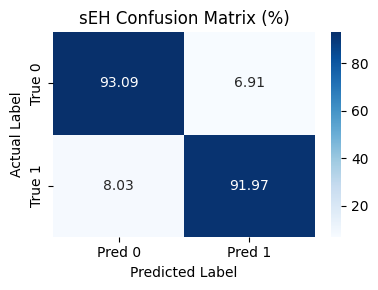

In [51]:
evaluation(model,test_loader,device)

In [52]:
from transformers import AutoTokenizer
import torch

# Load the same tokenizer you used during training
tokenizer = AutoTokenizer.from_pretrained("seyonec/ChemBERTa-zinc-base-v1")

def preprocess_smiles(smiles, max_length=128):
    encoding = tokenizer(smiles,
                         padding="max_length",
                         truncation=True,
                         max_length=max_length,
                         return_tensors="pt")
    return encoding["input_ids"], encoding["attention_mask"]


In [68]:
df = pd.read_parquet("train_multilabel_combined.parquet")
import pandas as pd

import pandas as pd

# Set display options to show full content
pd.set_option('display.max_columns', None)  # Show all columns
pd.set_option('display.max_colwidth', None)  # Show full width of each column
pd.set_option('display.width', None)  # Auto-detect terminal width
pd.set_option('display.max_rows', None)  # Show all rows if needed

# Assuming your DataFrame is named 'df'
random_rows = df.sample(n=10)

# Print with full display
print(random_rows.to_string())

                                                                           molecule_smiles  BRD4  HSA  sEH
1701502                      N#Cc1cc(Nc2nc(Nc3cc(F)ccn3)nc(N3CCCC[C@H]3C(=O)N[Dy])n2)ccc1F     0    0    0
1553224     CN(C)c1cccnc1CNc1nc(NC[C@H]2CC[C@H](C(=O)N[Dy])CC2)nc(Nc2ccc3c(c2)C(=O)CCC3)n1     0    0    1
1912726            Cc1nc(CCNc2nc(Nc3ccc4c(c3)CNC4=O)nc(N[C@@H](Cc3cscn3)C(=O)N[Dy])n2)sc1C     1    0    0
42534          CC(CNc1nc(Nc2ccc(N3CCOCC3)c(F)c2)nc(Nc2cc(Cl)nc(C(=O)N[Dy])c2Cl)n1)Cn1cccn1     0    0    0
463672   COC1CCC(CCNc2nc(NCc3cnc4c(c3)c(C)nn4C)nc(N[C@@H](Cc3csc4ccccc34)C(=O)N[Dy])n2)CC1     0    0    0
1663580                           O=C1CSC(Nc2nc(NCC3CCC(C(=O)N[Dy])CC3)nc(Nc3ccncn3)n2)=N1     0    0    1
2446223              O=C(N[Dy])[C@H]1CC[C@H](CNc2nc(NCC3CCC(C(F)F)CC3)nc(NCC3CCCOC3)n2)CC1     0    0    1
407845                  COc1cc(Nc2nc(NCc3cnc4n3CCOC4)nc(N[C@H](C(=O)N[Dy])C3CCCCC3)n2)ccn1     0    1    0
2379666                      O=C(N[Dy

In [54]:
def predict_smiles(model, smiles, device, threshold=0.5):
    model.eval()
    tokenizer = AutoTokenizer.from_pretrained("seyonec/ChemBERTa-zinc-base-v1")
    
    inputs = tokenizer(smiles, return_tensors="pt", padding=True, truncation=True, max_length=512)
    input_ids = inputs["input_ids"].to(device)
    attention_mask = inputs["attention_mask"].to(device)
    
    with torch.no_grad():
        logits = model(input_ids, attention_mask)
        probs = torch.sigmoid(logits).cpu().numpy().flatten()

    classes = ["BRD4", "HSA", "sEH"]
    binary_preds = (probs > threshold).astype(int)

    for cls, prob, pred in zip(classes, probs, binary_preds):
        print(f"{cls}: {'Binds' if pred == 1 else 'Does not bind'} (prob={prob:.4f})")

In [ ]:
# ---------------- Load Model ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Instantiate your model class
model = MultiLabelChemBERTaPlus()
model.load_state_dict(torch.load("best_multilabel_model.pt", map_location=device))  # Load weights
model.to(device)

# ---------------- Predict ----------------
test_smiles = "CC(C)Cc1ccc(C(=O)Nc2ccc(C(C)(C)C)cc2)cc1"
predict_smiles(model, test_smiles, device)

C:\Users\WALTON\AppData\Local\Temp\ipykernel_2952\2679084892.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_multilabel_model.pt",

BRD4: Binds (prob=0.7014)
HSA: Does not bind (prob=0.0597)
sEH: Does not bind (prob=0.0458)


In [75]:
# ---------------- Load Model ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Instantiate your model class
model = MultiLabelChemBERTaPlus()
model.load_state_dict(torch.load("best_multilabel_model.pt", map_location=device))  # Load weights
model.to(device)

# ---------------- Predict ----------------
test_smiles = "COc1cc(Nc2nc(NCc3cnc4n3CCOC4)nc(N[C@H](C(=O)N[Dy])C3CCCCC3)n2)ccn1"
predict_smiles(model, test_smiles, device)

C:\Users\WALTON\AppData\Local\Temp\ipykernel_2952\2197278694.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_multilabel_model.pt",

BRD4: Does not bind (prob=0.0211)
HSA: Binds (prob=0.8299)
sEH: Does not bind (prob=0.1052)


In [56]:
import pandas as pd


# Count total molecules
total = len(train_df)

# Individual protein binding counts
brd4_count = train_df["BRD4"].sum()
hsa_count = train_df["HSA"].sum()
seh_count = train_df["sEH"].sum()

# Count by binding pattern (e.g., 001, 010, etc.)
train_df["binding_combo"] = train_df[["BRD4", "HSA", "sEH"]].astype(str).agg("".join, axis=1)
combo_counts = train_df["binding_combo"].value_counts().sort_index()

# Binding count types
train_df["binding_count"] = train_df[["BRD4", "HSA", "sEH"]].sum(axis=1)
non_binding = (train_df["binding_count"] == 0).sum()
single_binding = (train_df["binding_count"] == 1).sum()
multi_binding = (train_df["binding_count"] >= 2).sum()

# Print all stats
print("✅ Protein-wise Binding Counts:")
print(f"BRD4 binders      : {int(brd4_count):,}")
print(f"HSA binders       : {int(hsa_count):,}")
print(f"sEH binders       : {int(seh_count):,}")
print("\n✅ Binding Pattern Counts:")
for pattern in sorted(combo_counts.index):
    print(f"{pattern} → {combo_counts[pattern]:,} molecules")
print("\n✅ Binding Class Distribution:")
print(f"Non-binding     (000): {non_binding:,}")
print(f"Single-binding       : {single_binding:,}")
print(f"Multiple-binding     : {multi_binding:,}")
print(f"\nTotal molecules: {total:,}")


✅ Protein-wise Binding Counts:
BRD4 binders      : 274,178
HSA binders       : 245,044
sEH binders       : 434,710

✅ Binding Pattern Counts:
000 → 100,000 molecules
001 → 386,812 molecules
010 → 197,363 molecules
011 → 47,503 molecules
100 → 273,642 molecules
101 → 358 molecules
110 → 141 molecules
111 → 37 molecules

✅ Binding Class Distribution:
Non-binding     (000): 100,000
Single-binding       : 857,817
Multiple-binding     : 48,039

Total molecules: 1,005,856


In [57]:
import pandas as pd


# Count total molecules
total = len(test_df)

# Individual protein binding counts
brd4_count = test_df["BRD4"].sum()
hsa_count = test_df["HSA"].sum()
seh_count = test_df["sEH"].sum()

# Count by binding pattern (e.g., 001, 010, etc.)
test_df["binding_combo"] = test_df[["BRD4", "HSA", "sEH"]].astype(str).agg("".join, axis=1)
combo_counts = test_df["binding_combo"].value_counts().sort_index()

# Binding count types
test_df["binding_count"] = test_df[["BRD4", "HSA", "sEH"]].sum(axis=1)
non_binding = (test_df["binding_count"] == 0).sum()
single_binding = (test_df["binding_count"] == 1).sum()
multi_binding = (test_df["binding_count"] >= 2).sum()

# Print all stats
print("✅ Protein-wise Binding Counts:")
print(f"BRD4 binders      : {int(brd4_count):,}")
print(f"HSA binders       : {int(hsa_count):,}")
print(f"sEH binders       : {int(seh_count):,}")
print("\n✅ Binding Pattern Counts:")
for pattern in sorted(combo_counts.index):
    print(f"{pattern} → {combo_counts[pattern]:,} molecules")
print("\n✅ Binding Class Distribution:")
print(f"Non-binding     (000): {non_binding:,}")
print(f"Single-binding       : {single_binding:,}")
print(f"Multiple-binding     : {multi_binding:,}")
print(f"\nTotal molecules: {total:,}")


✅ Protein-wise Binding Counts:
BRD4 binders      : 91,393
HSA binders       : 81,681
sEH binders       : 144,904

✅ Binding Pattern Counts:
000 → 240,000 molecules
001 → 128,938 molecules
010 → 65,788 molecules
011 → 15,834 molecules
100 → 91,214 molecules
101 → 120 molecules
110 → 47 molecules
111 → 12 molecules

✅ Binding Class Distribution:
Non-binding     (000): 240,000
Single-binding       : 285,940
Multiple-binding     : 16,013

Total molecules: 541,953


In [58]:
import pandas as pd


# Count total molecules
total = len(val_df)

# Individual protein binding counts
brd4_count = val_df["BRD4"].sum()
hsa_count = val_df["HSA"].sum()
seh_count = val_df["sEH"].sum()

# Count by binding pattern (e.g., 001, 010, etc.)
val_df["binding_combo"] = val_df[["BRD4", "HSA", "sEH"]].astype(str).agg("".join, axis=1)
combo_counts = val_df["binding_combo"].value_counts().sort_index()

# Binding count types
val_df["binding_count"] = val_df[["BRD4", "HSA", "sEH"]].sum(axis=1)
non_binding = (val_df["binding_count"] == 0).sum()
single_binding = (val_df["binding_count"] == 1).sum()
multi_binding = (val_df["binding_count"] >= 2).sum()

# Print all stats
print("✅ Protein-wise Binding Counts:")
print(f"BRD4 binders      : {int(brd4_count):,}")
print(f"HSA binders       : {int(hsa_count):,}")
print(f"sEH binders       : {int(seh_count):,}")
print("\n✅ Binding Pattern Counts:")
for pattern in sorted(combo_counts.index):
    print(f"{pattern} → {combo_counts[pattern]:,} molecules")
print("\n✅ Binding Class Distribution:")
print(f"Non-binding     (000): {non_binding:,}")
print(f"Single-binding       : {single_binding:,}")
print(f"Multiple-binding     : {multi_binding:,}")
print(f"\nTotal molecules: {total:,}")


✅ Protein-wise Binding Counts:
BRD4 binders      : 91,393
HSA binders       : 81,682
sEH binders       : 144,904

✅ Binding Pattern Counts:
000 → 240,000 molecules
001 → 128,938 molecules
010 → 65,788 molecules
011 → 15,834 molecules
100 → 91,214 molecules
101 → 119 molecules
110 → 47 molecules
111 → 13 molecules

✅ Binding Class Distribution:
Non-binding     (000): 240,000
Single-binding       : 285,940
Multiple-binding     : 16,013

Total molecules: 541,953


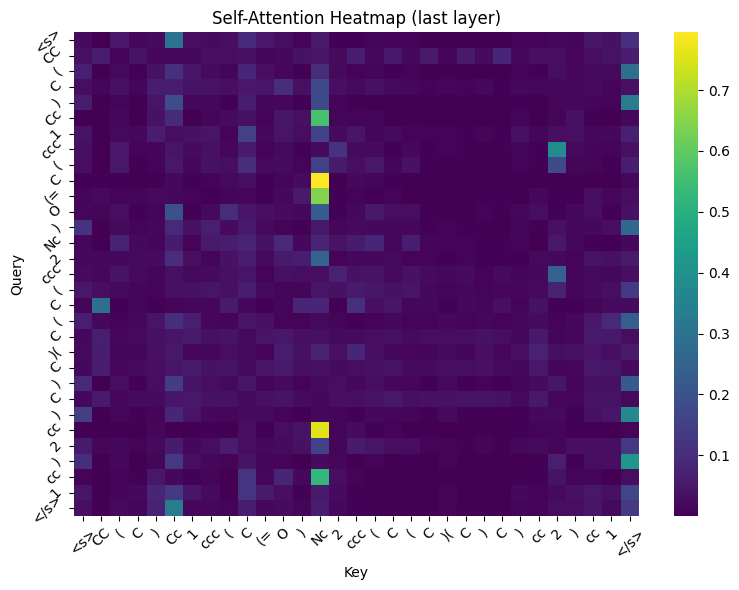

In [59]:
from transformers import AutoTokenizer, AutoModel
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# Load tokenizer and model with attention
tokenizer = AutoTokenizer.from_pretrained("seyonec/ChemBERTa-zinc-base-v1")
model = AutoModel.from_pretrained("seyonec/ChemBERTa-zinc-base-v1", output_attentions=True)
model.eval()

# Example SMILES input
smiles = "CC(C)Cc1ccc(C(=O)Nc2ccc(C(C)(C)C)cc2)cc1"  
inputs = tokenizer(smiles, return_tensors="pt")
with torch.no_grad():
    outputs = model(**inputs)

# Extract attention from last layer and head
attn = outputs.attentions[-1][0][0]  # shape: [seq_len, seq_len]

# Convert tokens to readable format
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

# Plot attention matrix
plt.figure(figsize=(8, 6))
sns.heatmap(attn.cpu().numpy(), xticklabels=tokens, yticklabels=tokens, cmap="viridis")
plt.title("Self-Attention Heatmap (last layer)")
plt.xlabel("Key")
plt.ylabel("Query")
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.tight_layout()
plt.show()
